# Assignment One: Automobile Price Analysis

**Student Name:** Victor Turyahebwa   
**Student Number:** B40815   
**Registration Number:** S26M19/041




## Introduction

This notebook explores the automobile dataset to find features that are related to car price. Price is the dependent variable. Features such as engine size, horsepower, body style and drive wheels are possible independent variables.

The analysis uses pandas commands, descriptive statistics and graphs. Correlation is used for feature selection.

## Question 1: Explore and clean the data

#### Load the dataset

In [72]:
# Import pandas to help read and work with the dataset.
import pandas as pd

# Import matplotlib to help in drawing graphs.
import matplotlib.pyplot as plt

# Read the CSV file and store the table in a variable called data.
# A question mark, if present in the dataset, will be treated as a missing value.
data = pd.read_csv("automobileEDA.csv", na_values="?")

# Show the first ten rows.
data.head(10)


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1
5,2,122,audi,std,two,sedan,fwd,front,99.8,0.851994,...,8.5,110.0,5500.0,19,25,15250.0,12.368421,Medium,0,1
6,1,158,audi,std,four,sedan,fwd,front,105.8,0.925997,...,8.5,110.0,5500.0,19,25,17710.0,12.368421,Medium,0,1
7,1,122,audi,std,four,wagon,fwd,front,105.8,0.925997,...,8.5,110.0,5500.0,19,25,18920.0,12.368421,Medium,0,1
8,1,158,audi,turbo,four,sedan,fwd,front,105.8,0.925997,...,8.3,140.0,5500.0,17,20,23875.0,13.823529,Medium,0,1
9,2,192,bmw,std,two,sedan,rwd,front,101.2,0.849592,...,8.8,101.0,5800.0,23,29,16430.0,10.217391,Low,0,1


The preview shows the first ten (10) car records. Each row is one record, while each column describes a feature. `price` is the value we want to understand.


In [73]:
import seaborn as sns

In [74]:
# shape shows the number of rows and columns.
print("Rows and columns:", data.shape)

# info shows column names, data types and the number of filled values.
data.info()


Rows and columns: (201, 29)
<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-syst

The dataset has **201 rows and 29 columns**. Numerical features include engine size, weight, horsepower and price. Text features include make, body style and drive wheels. `int64` means whole numbers, `float64` means numbers that can have decimal places, and `object` usually means text here. `symboling` is a coded risk category, while `diesel` and `gas` are fuel indicators coded as 0 and 1.


In [75]:
# Count the empty entries in each column.
print(data.isna().sum())

print("\n")

# Count rows that repeat all the values of an earlier row.
print("Duplicate rows:", data.duplicated().sum())


symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64


Duplicate rows: 0


There are **four missing stroke values**, **one missing horsepower category**, and **no exact duplicate rows**. `isna()` identifies empty entries, while `sum()` counts them in each column. Cars with similar specifications but different prices are not exact duplicates.


In [76]:
# Look at the records with no stroke measurement.
missing_stroke = data[data["stroke"].isna()]
print(missing_stroke[["make", "engine-type", "stroke"]])

print("\n")

# Look at the record with no horsepower category.
missing_category = data[data["horsepower-binned"].isna()]
print(missing_category[["make", "horsepower", "horsepower-binned"]])


     make engine-type  stroke
52  mazda       rotor     NaN
53  mazda       rotor     NaN
54  mazda       rotor     NaN
55  mazda       rotor     NaN


      make  horsepower horsepower-binned
46  jaguar       262.0               NaN


All four missing stroke entries belong to Mazda cars with rotary engines. A rotary engine produces power through a rotating rotor. Based on that design and the pattern in this file, I treat these stroke values as **not applicable**, rather than inventing a piston stroke value.

The missing horsepower category belongs to a Jaguar with **262 horsepower**. Its measured horsepower is available, so the missing category can be restored without changing the measurement.


In [77]:
# Check the horsepower ranges of the existing categories.
print(data.groupby("horsepower-binned")["horsepower"].min())

print("\n")

print(data.groupby("horsepower-binned")["horsepower"].max())

# Fill the one missing category as High because its horsepower is 262.
data["horsepower-binned"] = data["horsepower-binned"].fillna("High")

# Mark the four stroke values that do not apply to rotary engines.
data["stroke-not-applicable"] = data["stroke"].isna()

# Remove exact duplicate rows, if any. There are none in this file.
data = data.drop_duplicates()

print("\n")

print("Missing horsepower categories:", data["horsepower-binned"].isna().sum())
print("Stroke values marked not applicable:", data["stroke-not-applicable"].sum())


horsepower-binned
High      156.0
Low        48.0
Medium    102.0
Name: horsepower, dtype: float64


horsepower-binned
High      207.0
Low       101.0
Medium    155.0
Name: horsepower, dtype: float64


Missing horsepower categories: 0
Stroke values marked not applicable: 4


Existing Low horsepower entries range from 48 to 101, Medium entries from 102 to 155, and observed High entries from 156 to 207. The 262-horsepower car is therefore assigned to **High**. No horsepower category is now missing.

The four stroke entries stay blank and are marked `True` in the new `stroke-not-applicable` column. This is a deliberate cleaning decision. Filling these entries with an average would give rotary engines an artificial piston measurement. Later stroke summaries use the 197 available observations, and stroke is left out of feature selection.


In [78]:
# Store the names of the numerical measurements in a Python list.
numeric_columns = [
    "normalized-losses", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-size", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price",
    "city-L/100km"
]

# Select those columns from the table.
numeric_data = data[numeric_columns]

# Find the lower and upper quartiles of each numerical column.
q1 = numeric_data.quantile(0.25)
q3 = numeric_data.quantile(0.75)

# The interquartile range is the distance between the two quartiles.
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

# Flag values below or above these limits. The | symbol means OR.
below_limit = numeric_data < lower_limit
above_limit = numeric_data > upper_limit
outlier_flags = below_limit | above_limit

# Count the flagged entries in each column.
outlier_flags.sum()


normalized-losses     8
wheel-base            3
length                1
width                11
height                0
curb-weight           2
engine-size          10
bore                  0
stroke               20
compression-ratio    27
horsepower            5
peak-rpm              2
city-mpg              2
highway-mpg           3
price                14
city-L/100km          0
dtype: int64

The table gives the number of unusual values found by the **1.5 x IQR rule**. For example, price has **14 flagged entries**, engine size has **10**, and horsepower has **5**. An outlier is an unusual observation, not automatically a mistake. The same car may be flagged in several columns, so these counts should not be added to obtain a count of different cars.

The code uses separate lines for each step: find the quartiles, calculate the IQR, calculate the limits, and check which values fall outside them. Category codes and binary fuel indicators are excluded from this numerical outlier check.


In [79]:
# Copy the price outlier flags into the main table.
data["price-outlier"] = outlier_flags["price"]

# Display the prices and makes of the flagged cars.
expensive_cars = data[data["price-outlier"]]
print(expensive_cars[["make", "engine-size", "horsepower", "price"]])

print("\n")

print(f"Lower price limit: {lower_limit["price"]}")
print(f"Upper price limit: {upper_limit["price"]}")


              make  engine-size  horsepower    price
14             bmw          209       182.0  30760.0
15             bmw          209       182.0  41315.0
16             bmw          209       182.0  36880.0
44          jaguar          258       176.0  32250.0
45          jaguar          258       176.0  35550.0
46          jaguar          326       262.0  36000.0
67   mercedes-benz          183       123.0  31600.0
68   mercedes-benz          234       155.0  34184.0
69   mercedes-benz          234       155.0  35056.0
70   mercedes-benz          308       184.0  40960.0
71   mercedes-benz          304       184.0  45400.0
123        porsche          194       207.0  32528.0
124        porsche          194       207.0  34028.0
125        porsche          194       207.0  37028.0


Lower price limit: -5312.5
Upper price limit: 29587.5


The price limits are **-5,312.50 and 29,587.50**. All 14 price outliers lie above the upper limit. They include BMW, Jaguar, Mercedes-Benz and Porsche cars, with plausible high-end specifications. The supplied file gives no clear evidence that these are recording errors, so they are **retained and flagged**.

The other numerical outliers are also retained because a statistical flag alone does not establish an error. Removing all unusual cars would exclude part of the market. Medians and box plots are used alongside averages to show how high prices affect the results.


In [80]:
# Save the cleaned dataset.
# index=False prevents pandas from adding an extra row-number column.
data.to_csv("Turyahebwa_Data.csv", index=False)

print("Cleaned rows and columns:", data.shape)
print("Duplicate rows:", data.duplicated().sum())
print("Remaining blanks:", data.isna().sum().sum())


Cleaned rows and columns: (201, 31)
Duplicate rows: 0
Remaining blanks: 4


The cleaned file is **`Turyahebwa_Data.csv`**. It has **201 rows and 31 columns**, including the two cleaning flags. There are no exact duplicates. The **four remaining blanks are the explained stroke values**, not unfinished cleaning.


## Question 2: Descriptive statistics and distributions

#### Numerical summary

In [81]:
# describe gives counts, averages, standard deviations and quartiles.
# T turns the table so each measurement occupies one row.
# round(2) displays numbers to two decimal places.
numeric_summary = data[numeric_columns].describe().T
numeric_summary.round(2)


,count,mean,std,min,25%,50%,75%,max
normalized-losses,201.0,122.00,32.00,65.00,101.00,122.00,137.00,256.00
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94
stroke,197.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00


Prices range from **5,118 to 45,400**. The average is **13,207.13**, while the median, shown as `50%`, is **10,295**. The standard deviation is **7,947.07**, showing considerable price variation. The middle half of prices lies between **7,775 and 16,500**. The mean is above the median because high-price cars pull the average upward.

Average engine size is **126.88**, average curb weight **2,555.67**, and average horsepower **103.41**. Average city and highway fuel economy are **25.18 mpg and 30.69 mpg**. Stroke has a count of 197 because of the four inapplicable entries; the other numerical measurements have 201 entries.

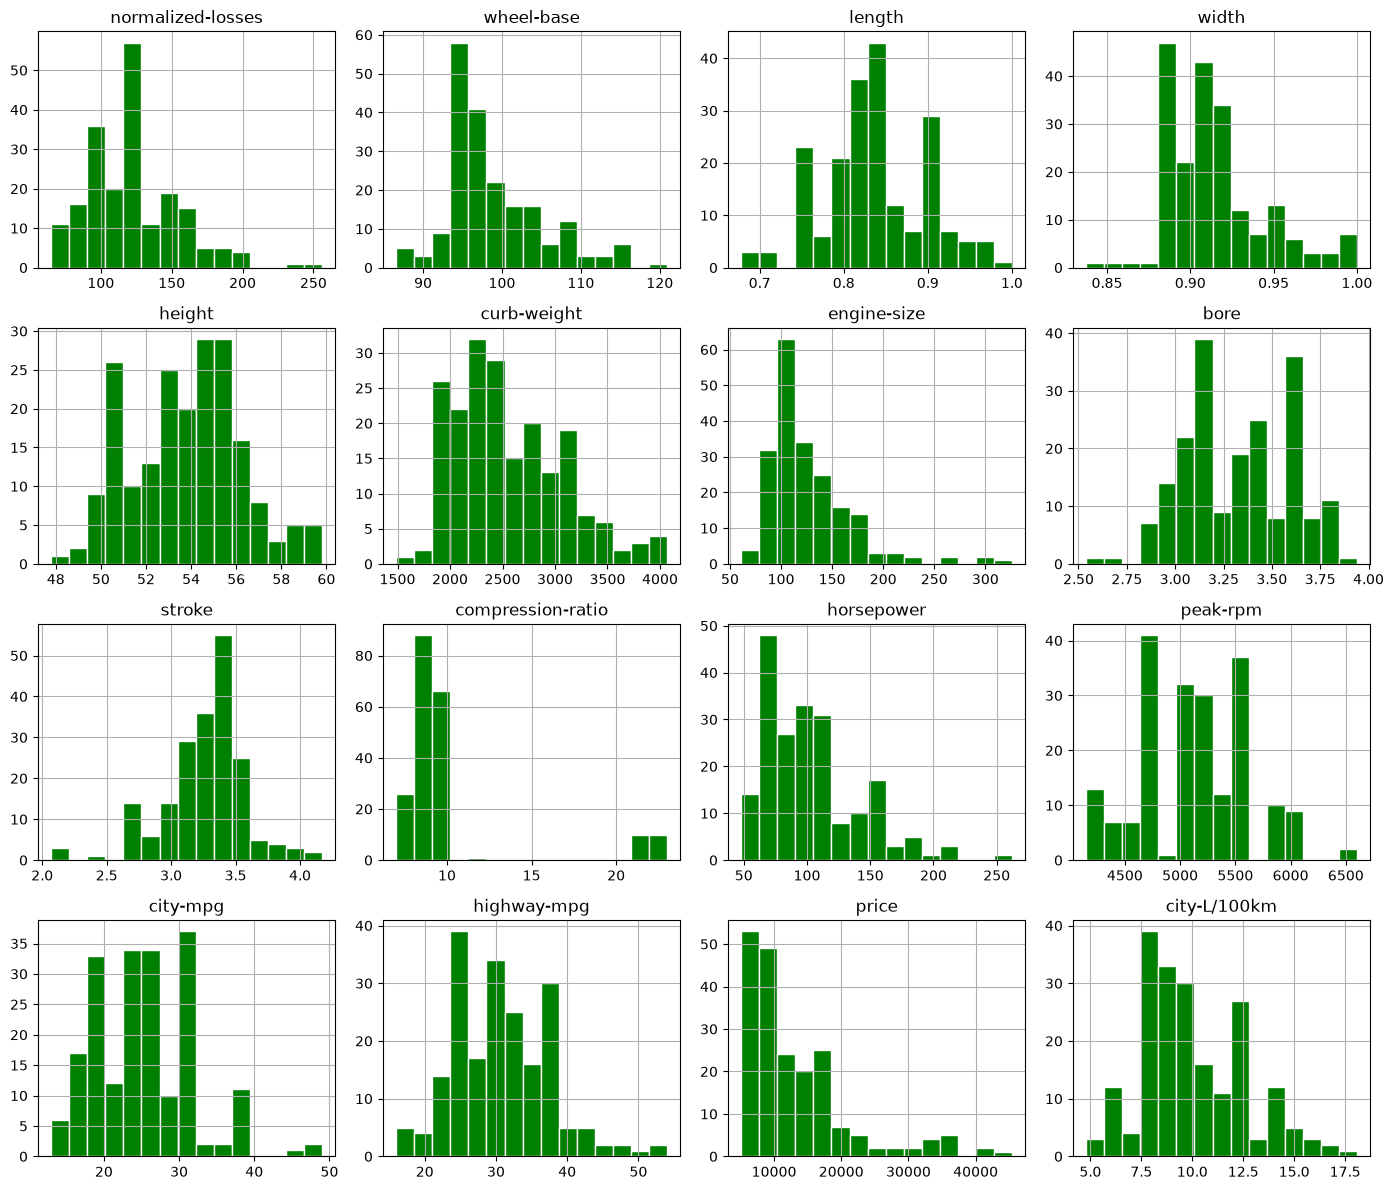

In [82]:
# Draw a histogram for every numerical measurement.
data[numeric_columns].hist(bins=15, figsize=(14, 12), color="green", edgecolor="white")
plt.tight_layout()
plt.show()


Engine size, weight and horsepower have longer upper tails. Height is more concentrated, while compression ratio has a separate high-value group. City and highway mpg have relatively few cars at their highest values. Length and width remain on their supplied normalised scales. The stroke histogram uses the 197 available measurements.

#### Categorical frequency counts

In [83]:
# value_counts counts the records in each category.

print(data["make"].value_counts())

print("\n")
print(data["body-style"].value_counts())

print("\n")
print(data["drive-wheels"].value_counts())

print("\n")
print(data["aspiration"].value_counts())


make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64


body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64


drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64


aspiration
std      165
turbo     36
Name: count, dtype: int64


Toyota is the most frequent make, with **32 cars**. Sedans have **94 records**, followed by hatchbacks with **68** and wagons with **25**. Front-wheel drive has **118 cars**, rear-wheel drive **75**, and four-wheel drive **8**. There are **165 standard-aspiration cars** and **36 turbo cars**. These groups are not equally represented.


In [84]:
# Count the other text categories.

print(data["num-of-doors"].value_counts())

print("\n")
print(data["engine-location"].value_counts())

print("\n")
print(data["engine-type"].value_counts())

print("\n")
print(data["num-of-cylinders"].value_counts())

print("\n")
print(data["fuel-system"].value_counts())


num-of-doors
four    115
two      86
Name: count, dtype: int64


engine-location
front    198
rear       3
Name: count, dtype: int64


engine-type
ohc      145
ohcf      15
ohcv      13
dohc      12
l         12
rotor      4
Name: count, dtype: int64


num-of-cylinders
four      157
six        24
five       10
two         4
eight       4
three       1
twelve      1
Name: count, dtype: int64


fuel-system
mpfi    92
2bbl    64
idi     20
1bbl    11
spdi     9
4bbl     3
mfi      1
spfi     1
Name: count, dtype: int64


There are **115 four-door cars** and **86 two-door cars**. Most engines are front-mounted (**198 cars**), while only **3** are rear-mounted. The most common engine type is `ohc` (**145 cars**), the most common cylinder category is four (**157 cars**), and the most common fuel system is `mpfi` (**92 cars**). Small groups should be interpreted cautiously because a few unusual records can change their averages substantially.


In [85]:
# Count horsepower groups and the categories stored as numerical codes.
print(data["horsepower-binned"].value_counts())

print("\n")
print(data["symboling"].value_counts())

print("\n")
print(data["diesel"].value_counts())

print("\n")
print(data["gas"].value_counts())


horsepower-binned
Low       115
Medium     62
High       24
Name: count, dtype: int64


symboling
 0    65
 1    52
 2    32
 3    27
-1    22
-2     3
Name: count, dtype: int64


diesel
0    181
1     20
Name: count, dtype: int64


gas
1    181
0     20
Name: count, dtype: int64


The repaired horsepower categories contain **115 Low, 62 Medium and 24 High** records. The risk codes range from -2 to 3, with code 0 occurring most often (**65 cars**). There are **20 diesel cars** and **181 gas cars**. For the binary fuel indicators, 1 means that the car uses that fuel and 0 means it does not. The diesel and gas columns describe the same fuel split in opposite form.


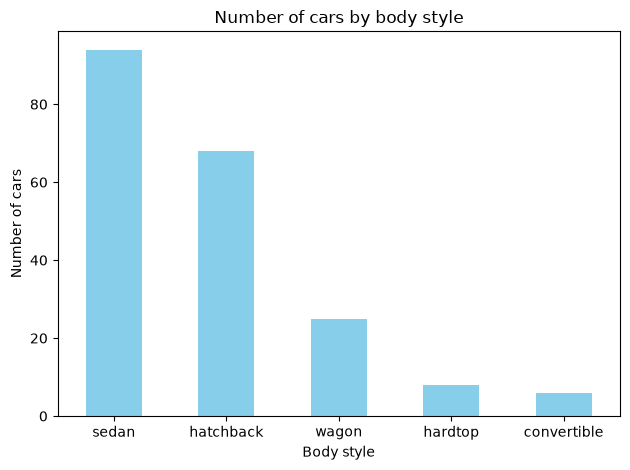

In [86]:
# Show how many cars belong to each body style.
data["body-style"].value_counts().plot(kind="bar", color="skyblue")
plt.title("Number of cars by body style")
plt.xlabel("Body style")
plt.ylabel("Number of cars")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Sedans and hatchbacks dominate the sample. Hardtops and convertibles are uncommon, with **8 and 6 cars** respectively. The graph therefore explains why averages for these two body styles have less support than the sedan or hatchback averages.


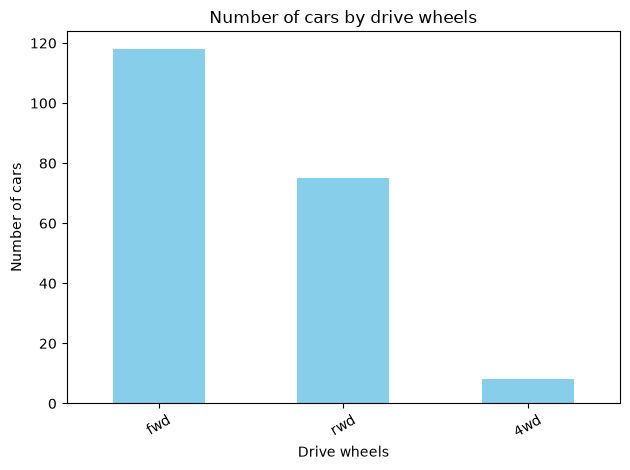

In [87]:
# Show how many cars belong to each drive-wheel group.
data["drive-wheels"].value_counts().plot(kind="bar", color="skyblue")
plt.title("Number of cars by drive wheels")
plt.xlabel("Drive wheels")
plt.ylabel("Number of cars")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Front-wheel drive is most common, followed by rear-wheel drive. Four-wheel drive has only eight observations. In the labels, `fwd` means front-wheel drive, `rwd` means rear-wheel drive, and `4wd` means four-wheel drive.


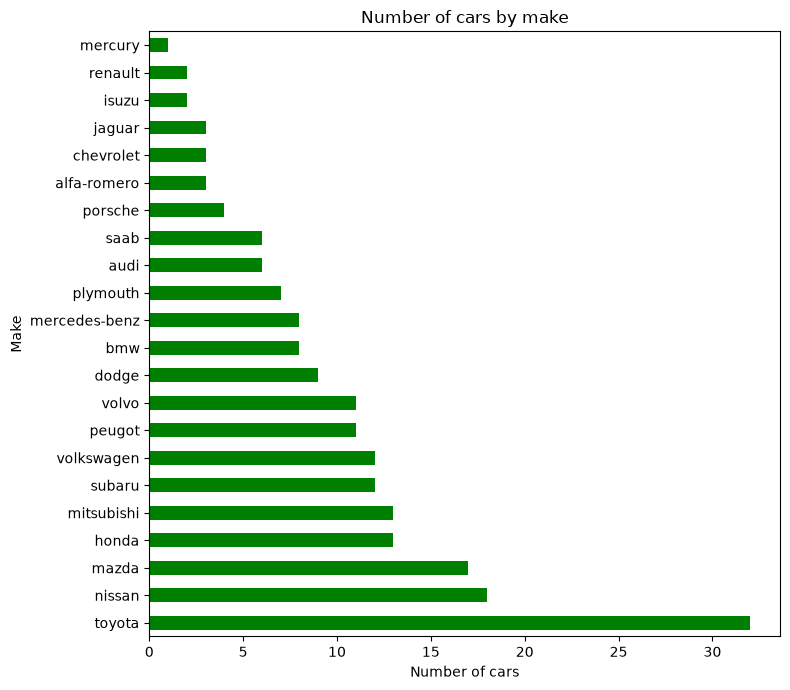

In [88]:
# A horizontal bar chart keeps the make names readable.
data["make"].value_counts().plot(kind="barh", figsize=(8, 7), color="green")
plt.title("Number of cars by make")
plt.xlabel("Number of cars")
plt.ylabel("Make")
plt.tight_layout()
plt.show()


Toyota has the largest number of records. Several makes have only one, two or three records, so their average prices should not be treated as reliable estimates for an entire manufacturer. The original make labels are kept as supplied, including the spelling `peugot`.


## Question 3: Group prices by car characteristics


#### Drive wheels

In [89]:
# Put cars into drive-wheel groups and describe price within each group.
data.groupby("drive-wheels")["price"].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
drive-wheels,,,,,,,,
4wd,8.0,10241.00,3288.21,7603.0,7984.25,9005.5,11367.75,17450.0
fwd,118.0,9244.78,3345.90,5118.0,6950.75,8192.0,10332.50,23875.0
rwd,75.0,19757.61,9082.58,6785.0,13455.00,16900.0,22547.50,45400.0


Rear-wheel drive has the highest average price, **19,757.61**, based on **75 cars**. Front-wheel drive has the lowest average, **9,244.78**, based on **118 cars**. Four-wheel drive averages **10,241.00**, based on only **8 cars**.

The medians are **16,900 for rear-wheel drive**, **8,192 for front-wheel drive**, and **9,005.50 for four-wheel drive**. The median comparison also places rear-wheel drive highest. `groupby()` puts matching categories together, and `describe()` then summarises price separately for each group.


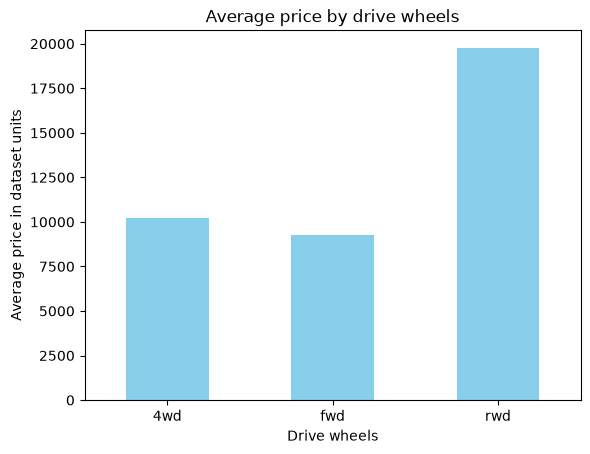

In [90]:
# Calculate and plot the average price for each drive-wheel group.
drive_means = data.groupby("drive-wheels")["price"].mean()
drive_means.plot(kind="bar", color="skyblue")
plt.title("Average price by drive wheels")
plt.xlabel("Drive wheels")
plt.ylabel("Average price in dataset units")
plt.xticks(rotation=0)
plt.show()


The rear-wheel-drive bar is much higher than the others. Its average exceeds the front-wheel-drive average by about **10,512.83 dataset units**. This describes the cars in these groups; it does not show that fitting rear-wheel drive alone would cause that price increase.

#### Body style

In [91]:
# Describe price separately for each body style.
data.groupby("body-style")["price"].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
body-style,,,,,,,,
convertible,6.0,21890.50,11187.80,11595.0,14246.25,17084.5,30709.25,37028.0
hardtop,8.0,22208.50,14555.52,8249.0,9341.50,19687.5,32903.00,45400.0
hatchback,68.0,9957.44,4148.86,5118.0,6518.75,8672.0,12044.75,22018.0
sedan,94.0,14459.76,8523.21,5499.0,8010.75,11078.5,17890.00,41315.0
wagon,25.0,12371.96,5120.95,6918.0,8013.00,11694.0,15750.00,28248.0


**Hardtops have the highest average price, 22,208.50**, followed closely by convertibles at **21,890.50**. **Hatchbacks have the lowest average, 9,957.44**. Sedans average **14,459.76**, and wagons **12,371.96**. The hardtop and convertible groups have only 8 and 6 cars, so these high means need caution. The table includes counts, medians, ranges and standard deviations to put each average in context.


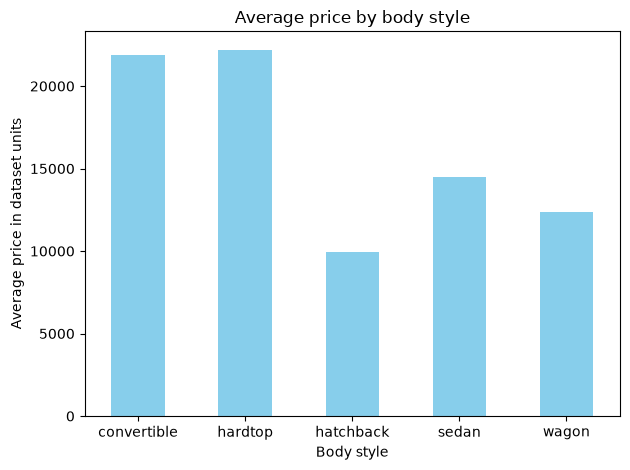

In [92]:
# Calculate and plot the average price for each body style.
body_means = data.groupby("body-style")["price"].mean()
body_means.plot(kind="bar", color="skyblue")
plt.title("Average price by body style")
plt.xlabel("Body style")
plt.ylabel("Average price in dataset units")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


The chart shows the high hardtop and convertible averages and the lower hatchback average. The gap between the highest and lowest averages is about **12,251.06**. Body style alone cannot explain all price differences because these groups also contain different makes and engine specifications.


In [93]:
# Group by both drive wheels and body style at the same time.
joint_means = data.groupby(["drive-wheels", "body-style"])["price"].mean()

# Sort the averages from highest to lowest.
joint_means.sort_values(ascending=False).round(2)


drive-wheels  body-style 
rwd           hardtop        24202.71
              convertible    23949.60
              sedan          21711.83
              wagon          16994.22
              hatchback      14337.78
4wd           sedan          12647.33
fwd           convertible    11595.00
              wagon           9997.33
              sedan           9811.80
4wd           wagon           9095.75
fwd           hatchback       8396.39
              hardtop         8249.00
4wd           hatchback       7603.00
Name: price, dtype: float64

Rear-wheel-drive hardtops have the highest observed combination average, **24,202.71**. Four-wheel-drive hatchbacks have the lowest, **7,603.00**. The first combination has **7 cars**, while the second has **only one car**, as the cross-tabulation in Question 4(c) shows. These combination averages are useful descriptions, but the small groups are unsuitable for fixed pricing rules.


## Question 4: Relationships with price 

### 4(a) Numerical variables and price

In [94]:
# Calculate the correlation between every pair of numerical columns.
correlation_table = data[numeric_columns].corr()

# Keep the price column from that correlation table.
price_correlations = correlation_table["price"]

# Remove price itself because a column always correlates perfectly with itself.
price_correlations = price_correlations.drop("price")

# Show the correlations from the most positive to the most negative.
price_correlations.sort_values(ascending=False).round(3)


engine-size          0.872
curb-weight          0.834
horsepower           0.810
city-L/100km         0.790
width                0.751
length               0.691
wheel-base           0.585
bore                 0.543
height               0.135
normalized-losses    0.134
stroke               0.082
compression-ratio    0.071
peak-rpm            -0.102
city-mpg            -0.687
highway-mpg         -0.705
Name: price, dtype: float64

Correlation ranges from **-1 to +1**. A positive value means the two measurements tend to rise together. A negative value means that one tends to fall as the other rises. A value near zero means a weak straight-line relationship.

The strongest positive relationships with price are **engine size (0.872)**, **curb weight (0.834)** and **horsepower (0.810)**. Width is also strongly related to price (**0.751**). Length has a correlation of **0.691**. Highway mpg and city mpg have negative correlations of **-0.705 and -0.687**: higher-mpg cars tend to be cheaper in this dataset.

`city-L/100km` has a positive correlation of **0.790**, but it is another way of expressing city fuel use. Higher litres per 100 km means lower efficiency, while higher mpg means greater efficiency. Height, stroke and compression ratio have much weaker linear relationships with price. The four blank stroke entries are omitted from stroke calculations automatically, leaving 197 pairs; other listed correlations use 201 pairs. Correlation does not prove cause and effect.


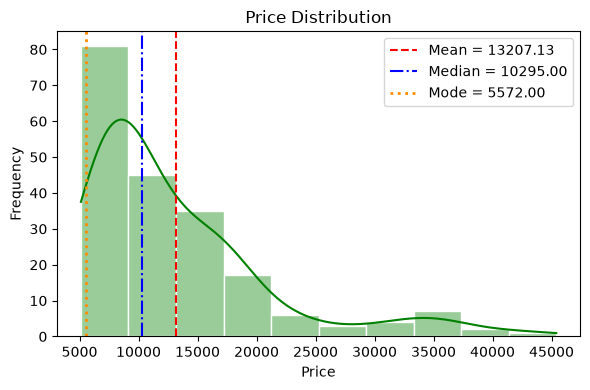

In [95]:
# Select price and graph its distribution.
price = data["price"]

# Calculate the three measures of central tendency.
price_mean_value = price.mean()
price_median_value = price.median()
price_mode_value = price.mode()[0]

# Set the chart size.
plt.figure(figsize=(6, 4))

# Draw the histogram.
# bins controls the number of bars.
# kde=True adds a smooth distribution curve.
sns.histplot(price, bins=10, kde=True, color="green", edgecolor="white", alpha=0.4)

# Add a red dashed line for the mean.
plt.axvline(price_mean_value, color="red", linestyle="--", label=f"Mean = {price_mean_value:.2f}")

# Add a blue dash-dot line for the median.
plt.axvline(price_median_value, color="blue", linestyle="-.", label=f"Median = {price_median_value:.2f}")

# Add an orange dotted line for the mode.
plt.axvline(price_mode_value, color="darkorange", linestyle=":", linewidth=2, label=f"Mode = {price_mode_value:.2f}")

# Add the title, axis labels and legend.
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

Most cars fall in the lower price ranges, while fewer cars have very high prices. The long tail to the right shows that price is **right-skewed**. 

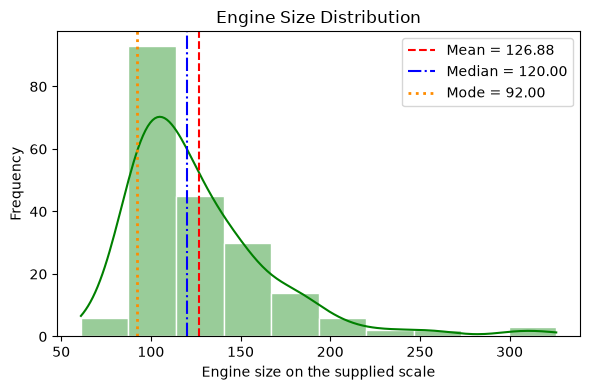

In [96]:
# Select engine size graph its distribution.
engine_size = data["engine-size"]

# Calculate the three measures of central tendency.
engine_size_mean_value = engine_size.mean()
engine_size_median_value = engine_size.median()
engine_size_mode_value = engine_size.mode()[0]

# Set the chart size.
plt.figure(figsize=(6, 4))

# Draw the histogram.
# bins controls the number of bars.
# kde=True adds a smooth distribution curve.
sns.histplot(engine_size, bins=10, kde=True, color="green", edgecolor="white", alpha=0.4)

# Add a red dashed line for the mean.
plt.axvline(engine_size_mean_value, color="red", linestyle="--", label=f"Mean = {engine_size_mean_value:.2f}")

# Add a blue dash-dot line for the median.
plt.axvline(engine_size_median_value, color="blue", linestyle="-.", label=f"Median = {engine_size_median_value:.2f}")

# Add an orange dotted line for the mode.
plt.axvline(engine_size_mode_value, color="darkorange", linestyle=":", linewidth=2, label=f"Mode = {engine_size_mode_value:.2f}")

# Add the title, axis labels and legend.
plt.title("Engine Size Distribution")
plt.xlabel("Engine size on the supplied scale")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

The engine-size distribution is **positively skewed (right-skewed)**, with one main peak around 100. Most cars have engine sizes of approximately **90–170**, while a few larger engines create a long right tail extending to about **330**.

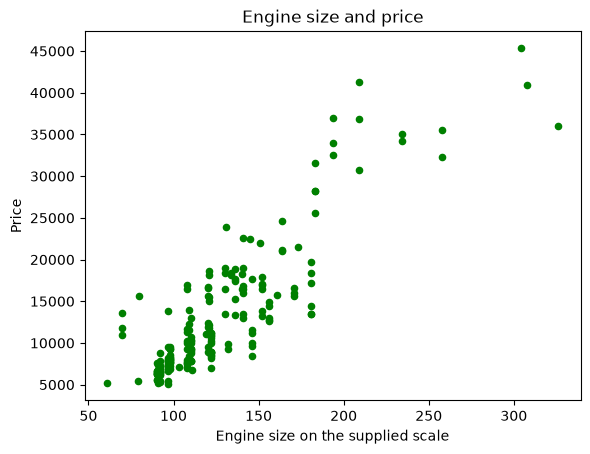

In [97]:
# Each dot compares engine size and price for one car.
data.plot(kind="scatter", x="engine-size", y="price", color="green")
plt.title("Engine size and price")
plt.xlabel("Engine size on the supplied scale")
plt.ylabel("Price")
plt.show()


The points generally rise from left to right. Larger engines tend to appear in more expensive cars. The points are not on a perfect line, so engine size does not explain every price difference.


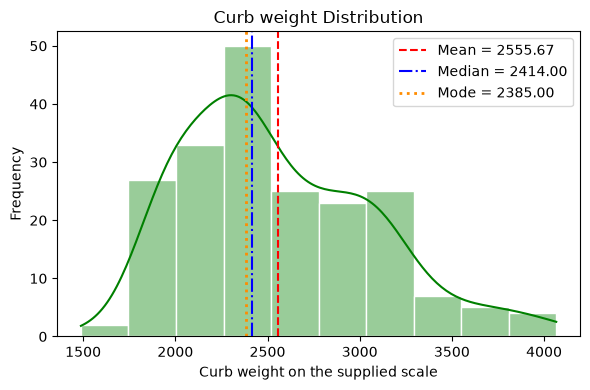

In [98]:
# Select curb weight and graph its distribution.
curb_weight = data["curb-weight"]

# Calculate the three measures of central tendency.
curb_weight_mean_value = curb_weight.mean()
curb_weight_median_value = curb_weight.median()
curb_weight_mode_value = curb_weight.mode()[0]

# Set the chart size.
plt.figure(figsize=(6, 4))

# Draw the histogram.
# bins controls the number of bars.
# kde=True adds a smooth distribution curve.
sns.histplot(curb_weight, bins=10, kde=True, color="green", edgecolor="white", alpha=0.4)

# Add a red dashed line for the mean.
plt.axvline(curb_weight_mean_value, color="red", linestyle="--", label=f"Mean = {curb_weight_mean_value:.2f}")

# Add a blue dash-dot line for the median.
plt.axvline(curb_weight_median_value, color="blue", linestyle="-.", label=f"Median = {curb_weight_median_value:.2f}")

# Add an orange dotted line for the mode.
plt.axvline(curb_weight_mode_value, color="darkorange", linestyle=":", linewidth=2, label=f"Mode = {curb_weight_mode_value:.2f}")

# Add the title, axis labels and legend.
plt.title("Curb weight Distribution")
plt.xlabel("Curb weight on the supplied scale")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

The curb-weight distribution is **positively skewed (right-skewed)**. Most cars have lower to moderate curb weights, with the highest concentration around **2,200–2,500**. A smaller number of heavier cars create a long right tail extending to approximately **4,100**.

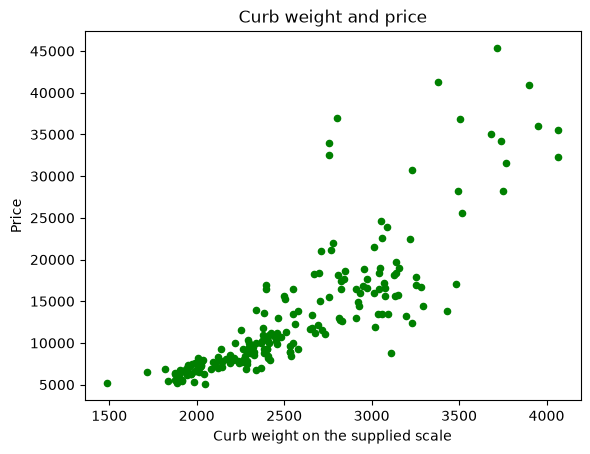

In [99]:
# Compare the weight of the car with its price.
data.plot(kind="scatter", x="curb-weight", y="price", color="green")
plt.title("Curb weight and price")
plt.xlabel("Curb weight on the supplied scale")
plt.ylabel("Price")
plt.show()


Heavier cars generally have higher prices. This supports the positive correlation of **0.834**. Weight may also be related to size and engine capacity, so this graph does not measure weight's separate effect after all other features are considered.


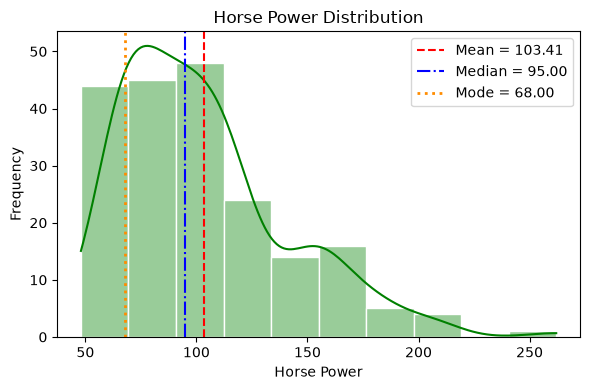

In [100]:
# Select Horse power and graph its distribution.
horse_power = data["horsepower"]

# Calculate the three measures of central tendency.
horse_power_mean_value = horse_power.mean()
horse_power_median_value = horse_power.median()
horse_power_mode_value = horse_power.mode()[0]

# Set the chart size.
plt.figure(figsize=(6, 4))

# Draw the histogram.
# bins controls the number of bars.
# kde=True adds a smooth distribution curve.
sns.histplot(horse_power, bins=10, kde=True, color="green", edgecolor="white", alpha=0.4)

# Add a red dashed line for the mean.
plt.axvline(horse_power_mean_value, color="red", linestyle="--", label=f"Mean = {horse_power_mean_value:.2f}")

# Add a blue dash-dot line for the median.
plt.axvline(horse_power_median_value, color="blue", linestyle="-.", label=f"Median = {horse_power_median_value:.2f}")

# Add an orange dotted line for the mode.
plt.axvline(horse_power_mode_value, color="darkorange", linestyle=":", linewidth=2, label=f"Mode = {horse_power_mode_value:.2f}")

# Add the title, axis labels and legend.
plt.title("Horse Power Distribution")
plt.xlabel("Horse Power")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

The horsepower distribution is **positively skewed (right-skewed)**. Most cars have horsepower values between approximately **50 and 130**, while a few more powerful cars create a long right tail extending to about **260**.

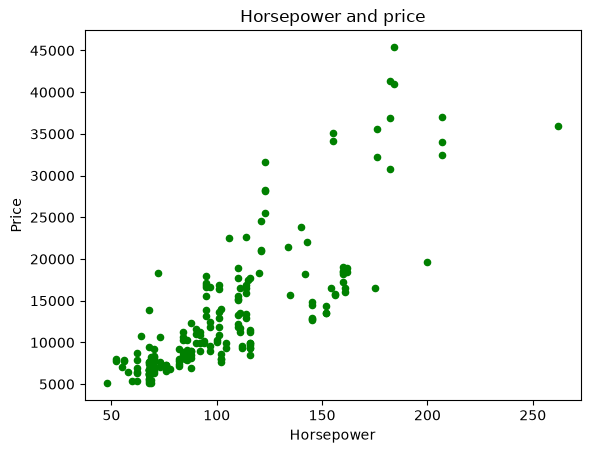

In [101]:
# Compare engine power with price.
data.plot(kind="scatter", x="horsepower", y="price", color="green")
plt.title("Horsepower and price")
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.show()


Cars with greater horsepower tend to cost more. Some cars with similar horsepower still have different prices. This shows why a dealer should use several relevant features when comparing cars.


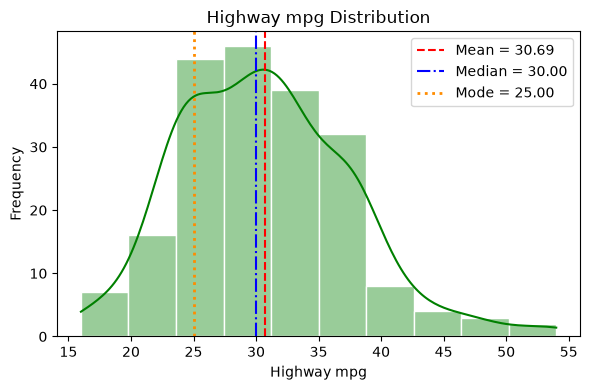

In [102]:
# Select Horse power and graph its distribution.
highway_mpg = data["highway-mpg"]

# Calculate the three measures of central tendency.
highway_mpg_mean_value = highway_mpg.mean()
highway_mpg_median_value = highway_mpg.median()
highway_mpg_mode_value = highway_mpg.mode()[0]

# Set the chart size.
plt.figure(figsize=(6, 4))

# Draw the histogram.
# bins controls the number of bars.
# kde=True adds a smooth distribution curve.
sns.histplot(highway_mpg, bins=10, kde=True, color="green", edgecolor="white", alpha=0.4)

# Add a red dashed line for the mean.
plt.axvline(highway_mpg_mean_value, color="red", linestyle="--", label=f"Mean = {highway_mpg_mean_value:.2f}")

# Add a blue dash-dot line for the median.
plt.axvline(highway_mpg_median_value, color="blue", linestyle="-.", label=f"Median = {highway_mpg_median_value:.2f}")

# Add an orange dotted line for the mode.
plt.axvline(highway_mpg_mode_value, color="darkorange", linestyle=":", linewidth=2, label=f"Mode = {highway_mpg_mode_value:.2f}")

# Add the title, axis labels and legend.
plt.title("Highway mpg Distribution")
plt.xlabel("Highway mpg")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

The highway-mpg distribution is **roughly mound-shaped with a slight positive (right) skew**. Most cars achieve approximately **24–39 mpg**, while a few cars with higher fuel efficiency extend the right tail to about **54 mpg**.

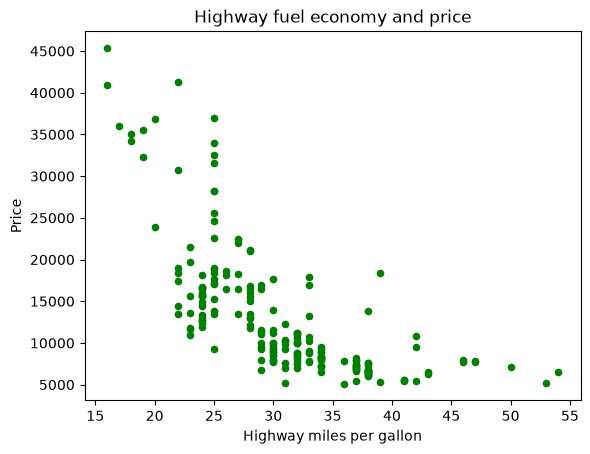

In [103]:
# Compare highway fuel economy with price.
data.plot(kind="scatter", x="highway-mpg", y="price", color="green")
plt.title("Highway fuel economy and price")
plt.xlabel("Highway miles per gallon")
plt.ylabel("Price")
plt.show()


The points generally slope downward. Many of the higher-mpg cars are cheaper, while expensive cars often have lower mpg. This is the negative relationship shown by **r = -0.705**. It does not mean that improving the efficiency of the same car would necessarily reduce its price.


### 4(b) Categorical variables and price


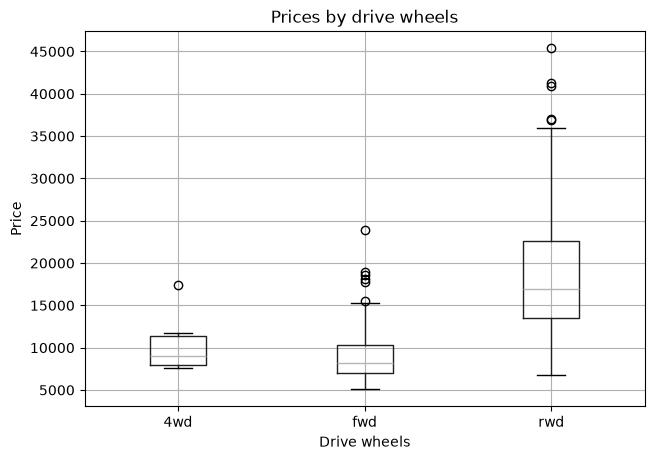

In [104]:
# A box plot compares the middle and spread of prices across groups.
data.boxplot(column="price", by="drive-wheels", figsize=(7, 5))
plt.title("Prices by drive wheels")
plt.suptitle("")
plt.xlabel("Drive wheels")
plt.ylabel("Price")
plt.show()


Rear-wheel-drive cars have a higher median price and a wider spread than front-wheel-drive cars. The line inside each box is the median. The box covers the middle half of the prices, and points beyond the whiskers are outliers. The groups overlap, so drivetrain does not determine an individual car's price.


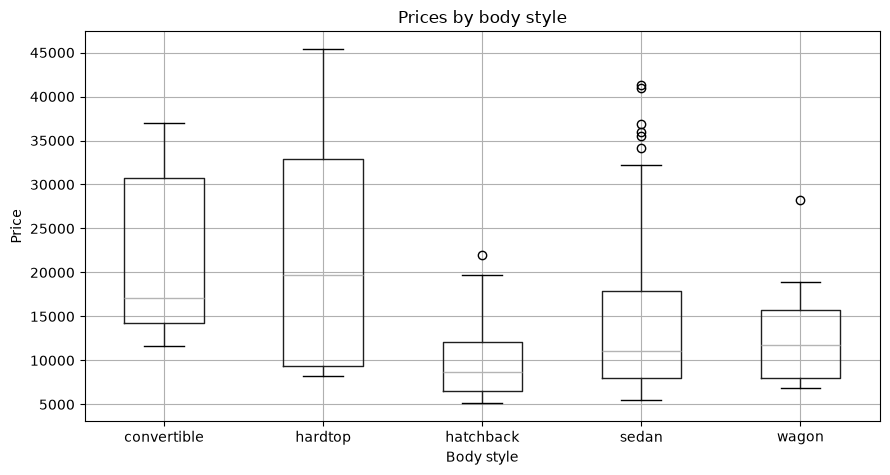

In [105]:
# Compare price distributions for the five body styles.
data.boxplot(column="price", by="body-style", figsize=(9, 5))
plt.title("Prices by body style")
plt.suptitle("")
plt.xlabel("Body style")
plt.ylabel("Price")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Hardtops and convertibles generally have higher prices than hatchbacks, but their ranges are wide and the groups are small. Sedans also cover a wide range of prices. The overlap reinforces the need to compare similar cars using several features, rather than body style alone.


In [106]:
# Compare average prices across several other categories.
print("AVERAGE PRICE BY MAKE")
print(data.groupby("make")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY ASPIRATION")
print(data.groupby("aspiration")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY HORSEPOWER CATEGORY")
print(data.groupby("horsepower-binned")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY NUMBER OF DOORS")
print(data.groupby("num-of-doors")["price"].mean().round(2))


AVERAGE PRICE BY MAKE
make
alfa-romero      15498.33
audi             17859.17
bmw              26118.75
chevrolet         6007.00
dodge             7875.44
honda             8184.69
isuzu             8916.50
jaguar           34600.00
mazda            10652.88
mercedes-benz    33647.00
mercury          16503.00
mitsubishi        9239.77
nissan           10415.67
peugot           15489.09
plymouth          7963.43
porsche          31400.50
renault           9595.00
saab             15223.33
subaru            8541.25
toyota            9885.81
volkswagen       10077.50
volvo            18063.18
Name: price, dtype: float64


AVERAGE PRICE BY ASPIRATION
aspiration
std      12542.18
turbo    16254.81
Name: price, dtype: float64


AVERAGE PRICE BY HORSEPOWER CATEGORY
horsepower-binned
High      26320.00
Low        9011.70
Medium    15913.02
Name: price, dtype: float64


AVERAGE PRICE BY NUMBER OF DOORS
num-of-doors
four    13498.03
two     12818.13
Name: price, dtype: float64


The make averages show that manufacturers occupy different price ranges in this sample. Small make groups need caution. Turbo cars average **16,254.81**, compared with **12,542.18** for standard-aspiration cars. High-horsepower cars average **26,320.00**, compared with **9,011.70** for Low-horsepower cars. The horsepower categories repeat information already found in the numerical horsepower column. The door averages show the observed group difference, but neither door count nor aspiration is isolated from make, size and power here.


In [107]:
# Examine the remaining categorical attributes using the same method.
print("AVERAGE PRICE BY ENGINE LOCATION")
print(data.groupby("engine-location")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY ENGINE TYPE")
print(data.groupby("engine-type")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY CYLINDER CATEGORY")
print(data.groupby("num-of-cylinders")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY FUEL SYSTEM")
print(data.groupby("fuel-system")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY RISK CODE")
print(data.groupby("symboling")["price"].mean().round(2))

print("\n")
print("AVERAGE PRICE BY DIESEL INDICATOR")
print(data.groupby("diesel")["price"].mean().round(2))


AVERAGE PRICE BY ENGINE LOCATION
engine-location
front    12884.09
rear     34528.00
Name: price, dtype: float64


AVERAGE PRICE BY ENGINE TYPE
engine-type
dohc     18116.42
l        14627.58
ohc      11567.36
ohcf     13738.60
ohcv     25098.38
rotor    13020.00
Name: price, dtype: float64


AVERAGE PRICE BY CYLINDER CATEGORY
num-of-cylinders
eight     38900.00
five      22007.60
four      10303.20
six       23671.83
three      5151.00
twelve    36000.00
two       13020.00
Name: price, dtype: float64


AVERAGE PRICE BY FUEL SYSTEM
fuel-system
1bbl     7555.55
2bbl     7433.20
4bbl    12145.00
idi     15838.15
mfi     12964.00
mpfi    17605.14
spdi    10990.44
spfi    11048.00
Name: price, dtype: float64


AVERAGE PRICE BY RISK CODE
symboling
-2    15781.67
-1    17330.68
 0    14397.09
 1     9648.65
 2    10109.28
 3    17221.30
Name: price, dtype: float64


AVERAGE PRICE BY DIESEL INDICATOR
diesel
0    12916.41
1    15838.15
Name: price, dtype: float64


These tables show additional category differences. Rear-mounted engines have a high mean, but there are only three records, so this result has little support. Some larger cylinder categories also have higher averages, while fuel systems and engine types divide the sample into different price groups. The diesel comparison also covers the gas contrast because the two indicators are complements.

These are descriptive comparisons do not establish that every difference is statistically significant, and they do not show the separate causal effect of each attribute. No formal significance test is claimed in this analysis.


### 4(c) Two categorical variables

In [108]:
# A cross-tabulation counts each combination of two categories.
category_counts = pd.crosstab(data["body-style"], data["drive-wheels"])
category_counts


drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,0,1,5
hardtop,0,1,7
hatchback,1,49,18
sedan,3,55,36
wagon,4,12,9


Sedans include **55 front-wheel-drive, 36 rear-wheel-drive and 3 four-wheel-drive cars**. Hatchbacks include **49 front-wheel-drive, 18 rear-wheel-drive and 1 four-wheel-drive car**. Hardtops and convertibles mostly have rear-wheel drive.

This comparison is between **two categorical variables**, rather than between a category and price. Counts describe the observed pattern; they do not by themselves prove a statistically significant association.


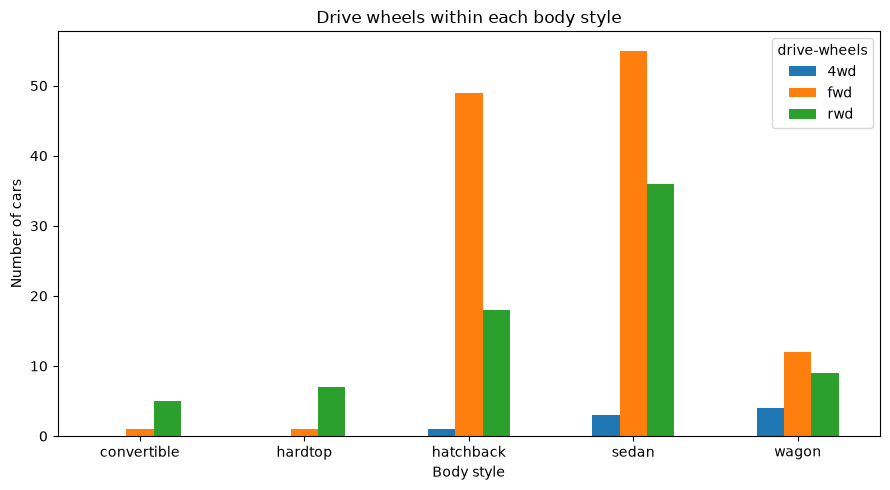

In [109]:
# Show the combination counts as a stacked bar chart.
category_counts.plot(kind="bar", stacked=False, figsize=(9, 5))
plt.title("Drive wheels within each body style")
plt.xlabel("Body style")
plt.ylabel("Number of cars")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Each bar represents a body style, and the colours show its drive-wheel groups. Front-wheel drive is common among sedans and hatchbacks, while rear-wheel drive is common among hardtops and convertibles. Taller bars also reflect larger body-style samples, so the graph should be read as counts rather than percentages.

In [110]:
# Group cars by both body style and drive wheels.
# count gives the number of cars; mean gives their average price.
combined_comparison = data.groupby(
    ["body-style", "drive-wheels"]
)["price"].agg(["count", "mean"])


# Show the number and average price for each combination.
combined_comparison.round(2)

count      mean
body-style  drive-wheels                 
convertible fwd               1  11595.00
            rwd               5  23949.60
hardtop     fwd               1   8249.00
            rwd               7  24202.71
hatchback   4wd               1   7603.00
            fwd              49   8396.39
            rwd              18  14337.78
sedan       4wd               3  12647.33
            fwd              55   9811.80
            rwd              36  21711.83
wagon       4wd               4   9095.75
            fwd              12   9997.33
            rwd               9  16994.22

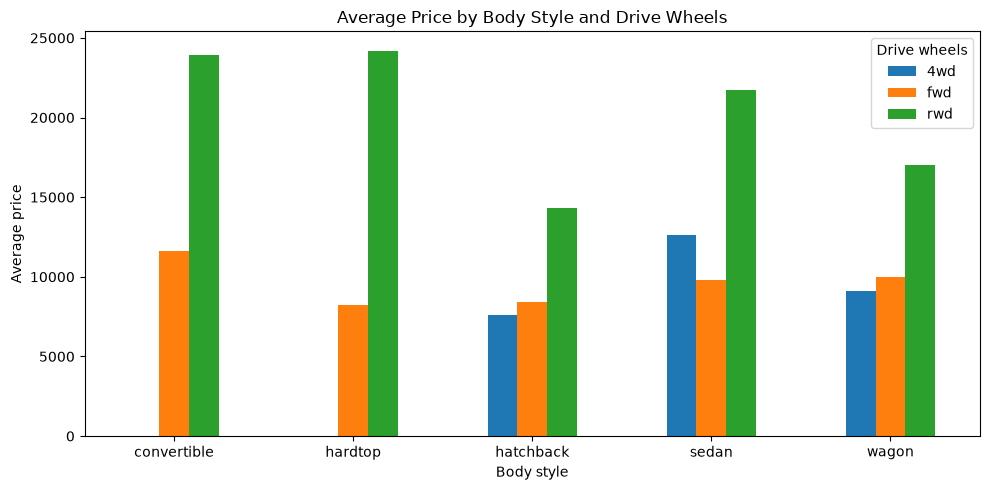

In [111]:
# Put the average prices into separate drive-wheel columns.
average_prices = combined_comparison["mean"].unstack()

# Draw a grouped bar chart.
average_prices.plot(kind="bar", figsize=(10, 5))

plt.title("Average Price by Body Style and Drive Wheels")
plt.xlabel("Body style")
plt.ylabel("Average price")
plt.legend(title="Drive wheels")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The grouped bar chart compares average car prices across body styles and drive-wheel types: four-wheel drive (4wd), front-wheel drive (fwd) and rear-wheel drive (rwd).

Rear-wheel-drive cars have the highest average price within every body style. Rear-wheel-drive hardtops and convertibles are the most expensive groups, averaging approximately 24,000, followed by rear-wheel-drive sedans at about 21,700.

Front-wheel-drive cars generally have lower average prices, ranging from approximately 8,200 to 11,600. Four-wheel-drive hatchbacks have the lowest average price overall, at about 7,600. Among sedans, four-wheel-drive cars cost more on average than front-wheel-drive cars.

## Question 5: Feature selection and recommendation



### Correlation-based feature selection

I use a **correlation filter** as a simple feature selection method. A numerical feature is selected if its **absolute correlation with price is at least 0.70**. Absolute value removes the sign so that strong negative relationships can also qualify. The threshold is a personal screening choice not a universal rule or proof of the best possible feature set.

Stroke is excluded because its measurement does not apply to the four rotary engines. `city-L/100km` is excluded because it repeats city fuel-use information. The two cleaning flags and the categorical codes are not included in this numerical screening. Categorical variables are considered separately through the earlier group comparisons.

In [112]:
# Remove the two numerical variables excluded from this screening step.
candidate_correlations = price_correlations.drop(["stroke", "city-L/100km"])

# abs changes negative values to positive values for strength comparisons.
correlation_strength = candidate_correlations.abs()

# Keep features whose absolute correlation is at least 0.70.
selected_features = correlation_strength[correlation_strength >= 0.70]

# Put the strongest selected features first.
selected_features = selected_features.sort_values(ascending=False)
selected_features.round(3)


engine-size    0.872
curb-weight    0.834
horsepower     0.810
width          0.751
highway-mpg    0.705
Name: price, dtype: float64

The method selects **engine size (0.872)**, **curb weight (0.834)**, **horsepower (0.810)**, **width (0.751)** and **highway mpg (absolute correlation 0.705)**. Highway mpg qualifies even though its original relationship is negative. These are correlation strengths, not percentages of price explained.

Length (**0.691**) and city mpg (**absolute value 0.687**) narrowly miss the chosen threshold; this does not make them useless. A different threshold could produce a different list. This filter only checks each feature's individual linear relationship with price. It does not measure unique importance after allowing for other features, and related features may repeat information. No prediction model is trained or evaluated here.


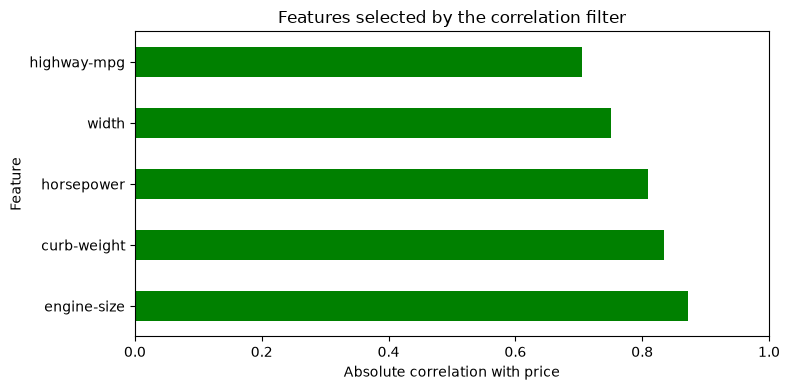

In [113]:
# Plot the strength of the five selected relationships.
selected_features.plot(kind="barh", color="green", figsize=(8, 4))
plt.title("Features selected by the correlation filter")
plt.xlabel("Absolute correlation with price")
plt.ylabel("Feature")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


Engine size has the longest bar, followed by curb weight and horsepower. Width and highway mpg also pass the 0.70 rule. The bars show strength only; the earlier correlation table gives the direction of each relationship. This graph summarises the feature selection result.

### Main findings

| Finding | Evidence from this dataset |
|---|---|
| Engine size, curb weight and horsepower are leading numerical price indicators. | Their price correlations are 0.872, 0.834 and 0.810. |
| Width and highway fuel economy also pass the feature selection rule. | Absolute correlations are 0.751 and 0.705. |
| Rear-wheel-drive cars have higher average prices. | Mean 19,757.61, compared with 9,244.78 for front-wheel drive. |
| Body style provides useful group context. | Hardtops have the highest mean, 22,208.50; hatchbacks have the lowest, 9,957.44. |
| Small groups and overlapping features limit interpretation. | Only 8 hardtops, 6 convertibles and 3 rear-engine cars; size, weight and power may be related. |

### Recommendation to a car dealer

Use engine size, weight, horsepower and vehicle dimensions when comparing similar cars. Also consider make, drive wheels and body style, while checking how many records support each group average.

### Conclusion

The analysis shows that engine size, curb weight and horsepower have the strongest numerical relationships with price. Width and highway fuel economy also qualify under the selected correlation rule. Drive wheels, body style and make help describe different price groups. These results identify useful pricing features, but they describe the supplied sample and do not prove cause and effect.

